## Exercise 2: Box–Muller and Marsaglia–Bray algorithms

Let $R$ be a random variable with Rayleigh distribution with parameter 1, and $\Theta$ a random variable with uniform distribution on $[0,2\pi]$, independent of $R$. The density of $R$ with respect to the Lebesgue measure is

$$
\forall r \in \mathbb{R}, \qquad
f_R(r) = r \exp\left(-\frac{r^2}{2}\right)\mathbf{1}_{\mathbb{R}_+}(r)
$$

**1.** Define $X$ and $Y$ by

$$
X = R\cos(\Theta)
\qquad \text{and} \qquad
Y = R\sin(\Theta)
$$

Prove that $X$ and $Y$ are independent with distribution $\mathcal{N}(0,1)$

**2.** Write an algorithm that samples independent $\mathcal{N}(0,1)$ variables from independent uniform variables (Box-Muller algorithm).

**3.** Consider the Marsaglia-Bray algorithm given above (Algorithm 1).

**a)** What is the distribution of $(V_1,V_2)$ at the end of the "while" loop?

**b)** What is the expected number of passes through the "while" loop?

**c)** Set

$$
T_1 = \frac{V_1}{\sqrt{V_1^2+V_2^2}}
\qquad \text{and} \qquad
V = V_1^2+V_2^2
$$

Show that $T_1$ and $V$ are independent, that $V \sim \mathcal{U}([0,1])$, and that $T_1$ has the same distribution as $\cos(\Theta)$ with $\Theta \sim \mathcal{U}([0,2\pi])$.

**d)** What is the distribution of the output $(X,Y)$?

---

#### **1.**
We know that $R$ and $\Theta$ are independant variables. so their joint density is : 
$$ 
f_{R,\Theta}(r,\theta) = f_R(r)\cdot f_\Theta (\theta) = f_R(r) = r \exp\left(-\frac{r^2}{2}\right)\mathbf{1}_{\mathbb{R}_+}(r) \cdot \frac{1}{2\pi}
$$

In order to prove that $X$ and $Y$ are independant, we just have to show that $f_{X,Y}(x,y) = f_X(x)f_Y(y)$. In order to do so we are going to make a change of variable.

 We know that $X=R\cos(\Theta)$ and $Y=R\sin(\Theta)$.
The determinant of the Jacobian is defined as : 
$$ |J|=
\begin{vmatrix}
\frac{\partial X}{\partial R} & \frac{\partial X}{\partial \Theta} \\
\frac{\partial Y}{\partial R} & \frac{\partial Y}{\partial \Theta}
\end{vmatrix}
= \begin{vmatrix}
\cos(\Theta) & -R\sin(\Theta) \\
\sin(\Theta) & R\cos(\Theta)
\end{vmatrix}
= R
$$

Moreover, we know that $R^2 = X^2 + Y^2$

So by using the change of variable formula for densities we have :
$$
\begin{aligned}
f_{X,Y}(x,Y) = \frac{f_{R,\Theta}(r,\theta)}{|J|}
&= \frac{1}{2\pi}\exp(-\frac{x^2 + y^2}{2})\\
&= \frac{1}{\sqrt{2\pi}}\exp(-\frac{x^2}{2})\cdot  \frac{1}{\sqrt{2\pi}}\exp(-\frac{y^2}{2})\\
&= f_X(x)\cdot f_Y(y)
\end{aligned}
$$

So the random variables $X$ and $Y$ are independant and they both follow a normal distribution $ \mathcal{N}(0,1)$ as seen with their respective densities. 

#### **2.**

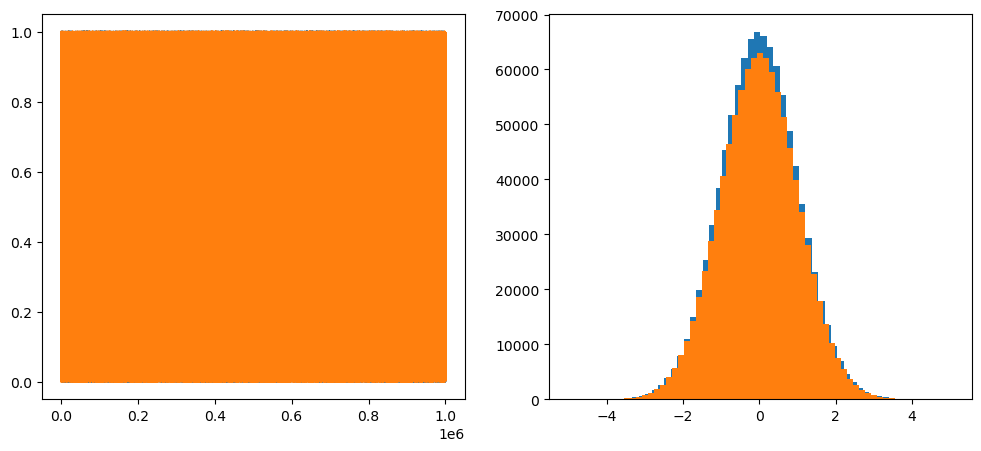

In [15]:
import numpy as np 
import matplotlib.pyplot as plt

def normal_box_muller(n):
    U_1 = np.random.uniform(1e-8, 1, n)
    U_2 = np.random.uniform(1e-8, 1, n)

    R = np.sqrt(-2*np.log(U_1))
    theta = 2*np.pi*U_2

    X = R*np.cos(theta)
    Y = R*np.sin(theta)

    return (U_1, U_2, X, Y)

def plot_variables(n):
    U_1, U_2, X, Y = normal_box_muller(n)
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    ax[0].plot(U_1, label='U(]0,1])')
    ax[0].plot(U_2, label='U(]0,1])')
    
    ax[1].hist(X, bins=60, label='N(0,1)')
    ax[1].hist(Y, bins=60,label='N(0,1)')

plot_variables(n=1000000)

#### **3.**

##### **a)**
We know that $U_1$ and $U_2$ both follow a uniform distribution between 0 and 1. We also know that in the "while" loop (when $V_1^2 + V_2^2 > 1$), at each iteration $U_1$ and $U_2$ are sampled and then $V_1$ and $V_2$ are respectively set to $2U_1 - 1$ and $2U_2 - 1$. So $V_1$ and $V_2$, at the end of the "while" loop, are uniformely distributed between -1 and +1 while also having $V_1^2 + V_2^2<1$ meaning that they are uniformely distributed on the unit circle. 

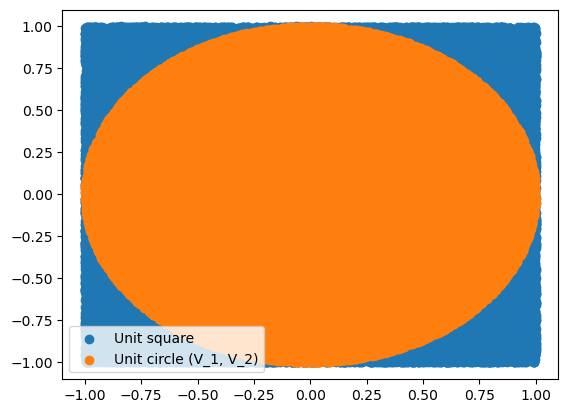

In [21]:
def end_of_loop():
    V_1 = 1
    V_2 = 1
    while V_1**2 + V_2**2 > 1 :
        U_1 = np.random.uniform(0, 1)
        U_2 = np.random.uniform(0, 1)

        V_1 = 2*U_1 - 1
        V_2 = 2*U_2 - 1

    W_1 = 2*np.random.uniform(0, 1) -1
    W_2 = 2*np.random.uniform(0, 1) -1

    return V_1, V_2, W_1, W_2

def plot_rd_unit_circle(n):
    rd_variables = [end_of_loop() for i in range(n)]

    V_1 = [rd_v[0] for rd_v in rd_variables]
    V_2 = [rd_v[1] for rd_v in rd_variables]
    W_1 = [rd_v[2] for rd_v in rd_variables]
    W_2 = [rd_v[3] for rd_v in rd_variables]

    plt.figure()
    plt.scatter(W_1, W_2, label='Unit square')
    plt.scatter(V_1, V_2, label='Unit circle (V_1, V_2)')
    plt.legend()
    plt.plot

plot_rd_unit_circle(100000)

##### **b)**
We know that we exit the loop when we are inside the unit circle. That means that the probability of exiting the loop is :
$$
p =\frac{\text{Area of the circle}}{\text{Area of the square}} = \frac{\pi}{4}
$$

Each iteration of the loop is independant therefore the number N of passes follows a geometric distribution. Meaning that the expected number of passes is :
$$
\begin{aligned}
\mathbb{E}(N) = \sum_{k=1}^{+\infty} k\mathbb{P}(N = k) &= \sum_{k=1}^{+\infty} kp(1-p)^{k-1} \\ &= -p\cdot \frac{d\left( (1-p)\frac{1}{1-(1-p)}\right)}{dp} \\
&= -p\cdot\frac{d\left( \frac{1}{p}-1\right)}{dp}\\
&= p\cdot \frac{1}{p^2}\\
&= \boxed{\frac{1}{p}}\\
&= \frac{4}{\pi} \simeq \boxed{1.27}
\end{aligned}
$$

##### **c)**
